In [18]:
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import numpy as np

CHECKPOINT = "../models/length_resource_experiment_256/checkpoint-339"

assert Path(CHECKPOINT).is_dir(), "Checkpoint not found"

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

model = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.eval()

MAX_LENGTH = 256

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 4544.59it/s]


In [2]:
print("Architecture:", model.config.model_type)
print("Number of Labels:", model.config.num_labels)
print("Label Mapping:", model.config.id2label)
print("Hidden Size:", model.config.dim)
print("Transformer Layers:", model.config.n_layers)
print("Attention Heads:", model.config.n_heads)
print("Maximum Positions:", model.config.max_position_embeddings)
print("Max Length:", MAX_LENGTH)
print("Total Parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", device)

Architecture: distilbert
Number of Labels: 3
Label Mapping: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
Hidden Size: 768
Transformer Layers: 6
Attention Heads: 12
Maximum Positions: 512
Max Length: 256
Total Parameters: 66955779
Device: cuda


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/financial_sentiment.csv")
df = df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)

print("Total Samples:", len(df))
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print(val_df["label"].value_counts().sort_index())

Total Samples: 2259
Train: 1807
Validation: 226
Test: 226
label
0     30
1    139
2     57
Name: count, dtype: int64


In [6]:
previous_predictions = pd.read_csv("../reports/prediction_disagreement.csv")

print(previous_predictions.columns.tolist())

val_df = val_df.reset_index(drop=True)

print(
    "Same Sentences:",
    set(val_df["sentence"]) == set(previous_predictions["sentence"])
)

print(
    "Same Order:",
    val_df["sentence"].equals(previous_predictions["sentence"])
)

print(
    "Same Labels:",
    val_df["label"].equals(previous_predictions["actual_label"])
)

['sentence', 'actual_label', 'token_count', 'prediction_128', 'prediction_256', 'same_prediction', 'correct_128', 'correct_256', 'group', 'truncated_128', 'truncated_256', 'lost_tokens_128', 'lost_tokens_256']
Same Sentences: True
Same Order: True
Same Labels: True


In [10]:
from datasets import Dataset, DatasetDict
from transformers import DataCollatorWithPadding

val_dataset = Dataset.from_pandas(val_df , preserve_index=False)

def tokenize_function(examples):
    encoded = tokenizer(
        examples["sentence"],
        truncation=True,
        max_length=256,
        padding=False,
        return_token_type_ids=False
    )

    return encoded


val_dataset = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["sentence"]
)

val_dataset



Map: 100%|██████████| 226/226 [00:00<00:00, 34046.14 examples/s]


Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 226
})

In [12]:
from torch.utils.data import DataLoader

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

val_dataloader = DataLoader(
    val_dataset , 
    batch_size=16,
    shuffle=False , 
    collate_fn=data_collator
)

print("Validation Batches :" , len(val_dataloader))


Validation Batches : 15


In [13]:
batch = next(iter(val_dataloader))

for key, value in batch.items():
    print(key, value.shape)

input_ids torch.Size([16, 43])
attention_mask torch.Size([16, 43])
labels torch.Size([16])


In [14]:
all_logits = []
all_labels = []

model.eval()

with torch.no_grad():
    for batch in val_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)

        all_logits.append(outputs.logits.cpu())
        all_labels.append(batch["labels"].cpu())

logits = torch.cat(all_logits, dim=0)
labels = torch.cat(all_labels, dim=0)

print("Logits Shape:", logits.shape)
print("Labels Shape:", labels.shape)

Logits Shape: torch.Size([226, 3])
Labels Shape: torch.Size([226])


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

predictions = torch.argmax(logits, dim=1)

accuracy = accuracy_score(labels.numpy(), predictions.numpy())

macro_f1 = f1_score(
    labels.numpy(),
    predictions.numpy(),
    average="macro"
)

print(f"Accuracy: {accuracy:.6f}")
print(f"Macro-F1: {macro_f1:.6f}")

Accuracy: 0.969027
Macro-F1: 0.958797


In [19]:
previous_predictions = pd.read_csv("../reports/prediction_disagreement.csv")

np.array_equal(predictions , previous_predictions["prediction_256"].to_numpy())


True

In [29]:
probabilities = torch.softmax(logits , dim=1)
print( "Probabilities[5] : " ,probabilities[:5])

confidence , predicted_labels = torch.max(probabilities , dim=1)

print("Confidence Shape : " , confidence.shape)
print("Predicted_Labels Shape :" , predicted_labels.shape)

Probabilities[5] :  tensor([[0.0021, 0.9938, 0.0041],
        [0.0161, 0.0079, 0.9761],
        [0.0157, 0.0070, 0.9773],
        [0.9538, 0.0132, 0.0330],
        [0.0020, 0.9941, 0.0039]])
Confidence Shape :  torch.Size([226])
Predicted_Labels Shape : torch.Size([226])


In [30]:
assert torch.all((probabilities >= 0) & (probabilities <= 1))
assert torch.allclose(probabilities.sum(dim=1), torch.ones(226), atol=1e-6)
assert torch.equal(predicted_labels, torch.argmax(logits, dim=1))

print("All probability tests passed.")

All probability tests passed.


In [39]:
correct_mask = predicted_labels == labels
incorrect_mask = ~correct_mask


print("Correct Predictions :" , correct_mask.sum())
print("Incorrect Predictions : " , incorrect_mask.sum())

Correct Predictions : tensor(219)
Incorrect Predictions :  tensor(7)


In [ ]:
correct_confidence = confidence[correct_mask]
incorrect_confidence = confidence[incorrect_mask]

print(correct_confidence.mean())


all_confidence = pd.DataFrame({
    "Correct": pd.Series(correct_confidence.numpy()),
    "Incorrect": pd.Series(incorrect_confidence.numpy())
})
confidence_analysis = all_confidence.describe()

confidence_analysis.to_csv(
    "../reports/confidence_analysis.csv",
    index=True
)

confidence_analysis



tensor(0.9680)


,Correct,Incorrect
count,219.000000,7.000000
mean,0.968019,0.843052
std,0.067903,0.173471
min,0.562891,0.494969
25%,0.970977,0.787980
50%,0.991638,0.935531
75%,0.993879,0.960816
max,0.994631,0.973275


In [72]:
bin_boundaries = torch.linspace(0.0 , 1.0 , 6)

for lower, upper in zip(bin_boundaries[:-1], bin_boundaries[1:]):
    print(lower.item(), upper.item())
    bin_mask = (confidence > lower.item()) & (confidence <= upper.item())
    bin_confidence = confidence[bin_mask].mean()
    bin_accuracy = correct_mask[bin_mask].float().mean()
    bin_weight = bin_mask.sum() / len(confidence)
    bin_ece = bin_weight * abs(bin_accuracy - bin_confidence)
    print(f"ECE  : {lower.item()} - {upper.item()} : {bin_ece.item()}")
    print("")

0.0 0.20000000298023224
ECE  : 0.0 - 0.20000000298023224 : nan

0.20000000298023224 0.4000000059604645
ECE  : 0.20000000298023224 - 0.4000000059604645 : nan

0.4000000059604645 0.6000000238418579
ECE  : 0.4000000059604645 - 0.6000000238418579 : 0.003372133243829012

0.6000000238418579 0.800000011920929
ECE  : 0.6000000238418579 - 0.800000011920929 : 0.001649596611969173

0.800000011920929 1.0
ECE  : 0.800000011920929 - 1.0 : 0.0001434174773748964



In [ ]:
def calculate_ece(confidence, correct_mask, n_bins=5):
    bin_boundaries = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_results = []

    for lower, upper in zip(bin_boundaries[:-1], bin_boundaries[1:]):

        if lower == 0:
            bin_mask = (confidence >= lower) & (confidence <= upper)
        else:
            bin_mask = (confidence > lower) & (confidence <= upper)

        count = bin_mask.sum().item()

        if count == 0:
            bin_results.append({
                "lower": lower.item(),
                "upper": upper.item(),
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan
            })
            continue

        bin_confidence = confidence[bin_mask].mean()
        bin_accuracy = correct_mask[bin_mask].float().mean()
        bin_weight = count / len(confidence)

        bin_ece = bin_weight * abs(bin_accuracy - bin_confidence)

        ece += bin_ece.item()

        bin_results.append({
            "lower": lower.item(),
            "upper": upper.item(),
            "count": count,
            "mean_confidence": bin_confidence.item(),
            "accuracy": bin_accuracy.item()
        })

    return ece, pd.DataFrame(bin_results)


overall_ece, bin_results = calculate_ece(confidence, correct_mask)

print(f"Overall ECE: {overall_ece:.6f}")

bin_results


Overall ECE: 0.005165


,lower,upper,count,mean_confidence,accuracy
0,0.0,0.2,0,NaN,NaN
1,0.2,0.4,0,NaN,NaN
2,0.4,0.6,4,0.559474,0.750000
3,0.6,0.8,9,0.736355,0.777778
4,0.8,1.0,213,0.981373,0.981221


In [86]:
negative_probs = probabilities[: ,0]
negative_targets = labels == 0

negatove_overall_ece, negative_bin_results = calculate_ece(negative_probs, negative_targets)

print(f"Overall ECE: {negatove_overall_ece:.6f}")

negative_bin_results

Overall ECE: 0.010792


,lower,upper,count,mean_confidence,accuracy
0,0.0,0.2,193,0.008041,0.005181
1,0.2,0.4,2,0.280792,0.000000
2,0.4,0.6,0,NaN,NaN
3,0.6,0.8,1,0.689492,1.000000
4,0.8,1.0,30,0.967163,0.933333


In [87]:
class_names = ["Negative", "Neutral", "Positive"]

classwise_results = []
classwise_bins = {}

for class_id, class_name in enumerate(class_names):

    class_probs = probabilities[:, class_id]
    class_targets = labels == class_id

    class_ece, class_bins = calculate_ece(
        class_probs,
        class_targets,
        n_bins=5
    )

    classwise_results.append({
        "class": class_name,
        "mean_predicted_probability": class_probs.mean().item(),
        "actual_class_rate": class_targets.float().mean().item(),
        "ece": class_ece
    })

    classwise_bins[class_name] = class_bins

classwise_df = pd.DataFrame(classwise_results)

classwise_df

,class,mean_predicted_probability,actual_class_rate,ece
0,Negative,0.140787,0.132743,0.010792
1,Neutral,0.593558,0.615044,0.024971
2,Positive,0.265655,0.252212,0.017487


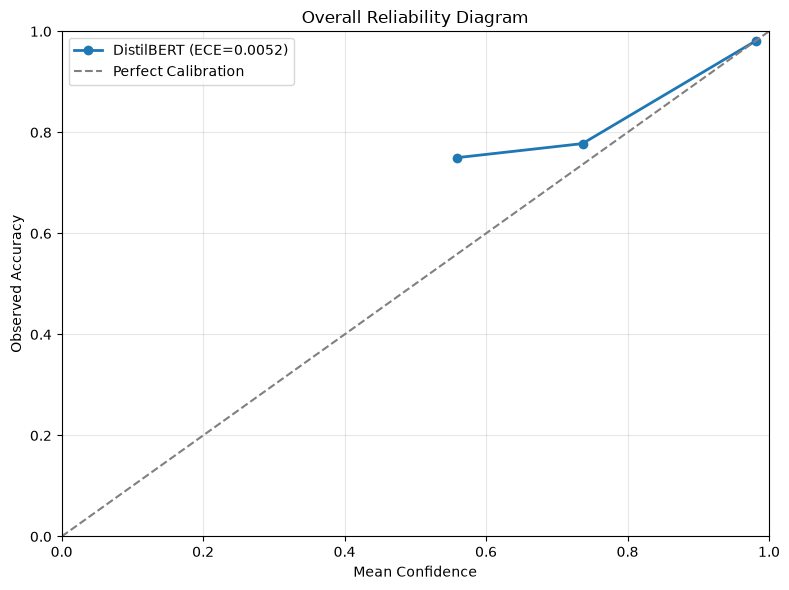

In [88]:
import matplotlib.pyplot as plt

valid_bins = bin_results.dropna()

plt.figure(figsize=(8, 6))

plt.plot(
    valid_bins["mean_confidence"],
    valid_bins["accuracy"],
    marker="o",
    linewidth=2,
    label=f"DistilBERT (ECE={overall_ece:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Mean Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Overall Reliability Diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/reliability_diagram.png", dpi=300)
plt.show()

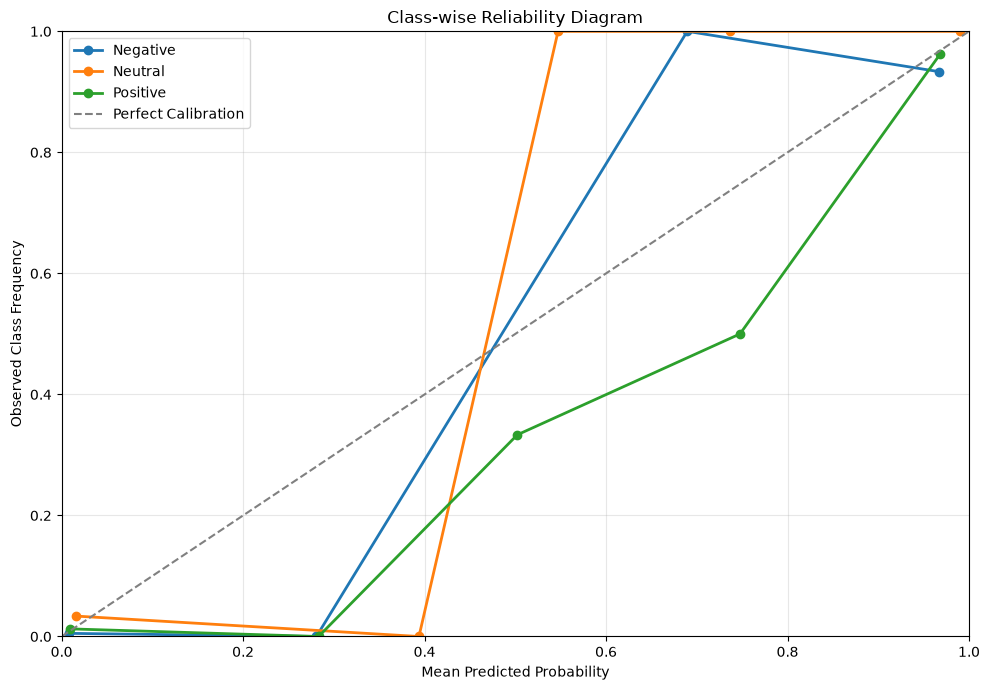

In [89]:
plt.figure(figsize=(10, 7))

for class_name, class_bins in classwise_bins.items():

    valid_bins = class_bins.dropna()

    plt.plot(
        valid_bins["mean_confidence"],
        valid_bins["accuracy"],
        marker="o",
        linewidth=2,
        label=class_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Class Frequency")
plt.title("Class-wise Reliability Diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/classwise_calibration.png", dpi=300)
plt.show()

In [99]:
pd.set_option("display.max_colwidth", None)

predictions_df = val_df.copy()

predictions_df["row_id"] = predictions_df.index

predictions_df["predicted"] = predicted_labels.numpy()

predictions_df["confidence"] = confidence.numpy()

predictions_df["p_negative"] = probabilities[:, 0].numpy()

predictions_df["p_neutral"] = probabilities[:, 1].numpy()

predictions_df["p_positive"] = probabilities[:, 2].numpy()

predictions_df["is_correct"] = correct_mask.numpy()

predictions_df["token_length"] = previous_predictions["token_count"]

predictions_df.head()

error_df = predictions_df[~predictions_df["is_correct"]].copy()
error_df.sort_values(by="confidence" , ascending=False)

,sentence,label,row_id,predicted,confidence,p_negative,p_neutral,p_positive,is_correct,token_length
149,"ADP News - Apr 22 , 2009 - Finnish business information systems developer Solteq Oyj HEL : STQ1V said today its net loss widened to EUR 189,000 USD 245,000 for the first quarter of 2009 from EUR 10,000 for the same peri",0,149,2,0.973275,0.019524,0.007201,0.973275,False,62
31,Unit costs for flight operations fell by 6.4 percent .,2,31,0,0.967017,0.967017,0.016452,0.016531,False,14
180,The new factory working model and reorganisations would decrease Nokian Tyres ' costs in the factory by EUR 30 million ( USD 38.7 m ) .,2,180,0,0.954615,0.954615,0.011345,0.034040,False,33
10,Nordea was the cheapest also for a couple in their 30s with debt .,1,10,2,0.935531,0.025434,0.039035,0.935531,False,19
172,Shuweihat 2 got under way in July 2008 when the project was awarded to desalination and power contractors .,1,172,2,0.788960,0.019124,0.191915,0.788960,False,25
190,"According to Finnish Scanfil 's founder and chairman of the board , Jorma J. Takanen , the company has to look for growth abroad .",1,190,2,0.787000,0.016116,0.196884,0.787000,False,34
146,"In the first quarter of 2008 , Sacanfil 's net sales totalled EUR 50.0 mn and its operating profit EUR 4.7 mn .",1,146,2,0.494969,0.015228,0.489803,0.494969,False,36


Row ID	Gerçek	Tahmin	Confidence	Olası hata nedeni
149	Negative	Positive	%97,33	Net zararın büyümesini yanlış yorumlama
31	Positive	Negative	%96,70	Maliyet düşüşünü olumsuz algılama
180	Positive	Negative	%95,46	Maliyet azaltımını olumsuz algılama
10	Neutral	Positive	%93,55	Fiyat avantajı ile finansal duygu karışıklığı
172	Neutral	Positive	%78,90	Şirket faaliyetini olumlu gelişme olarak yorumlama
190	Neutral	Positive	%78,70	Büyüme hedefini gerçekleşmiş başarı olarak yorumlama
146	Neutral	Positive	%49,50	Karşılaştırma içermeyen finansal rakamları olumlu yorumlama

En önemli bulgular
1. Financial semantic misunderstanding

31 ve 180 numaralı örneklerde maliyetlerin düşmesi olumlu bir gelişme. Ancak model bunu Negative olarak sınıflandırmış.

Model, düşüş belirten kelimelere aşırı önem veriyor olabilir. Bunu kesinleştirmek için ek örneklerle test etmek gerekir.

2. Confidence problemi

Yedi hatanın dördünde confidence %90'ın üzerinde.

3. Truncation problemi yok

Yanlış tahminlerdeki en yüksek token uzunluğu 62. Dolayısıyla 256 token sınırı nedeniyle bilgi kaybı yaşanmadı.

In [100]:
error_reasons = {
    149: "Misinterpretation of increasing net loss",
    31: "Misinterpretation of cost reduction",
    180: "Misinterpretation of cost savings",
    10: "Confusion between price advantage and positive sentiment",
    172: "Company activity interpreted as positive sentiment",
    190: "Growth objective interpreted as achieved growth",
    146: "Financial figures without directional comparison"
}

error_df["error_reason"] = error_df["row_id"].map(error_reasons)

error_df[["row_id", "label", "predicted", "confidence", "error_reason"]]

,row_id,label,predicted,confidence,error_reason
10,10,1,2,0.935531,Confusion between price advantage and positive sentiment
31,31,2,0,0.967017,Misinterpretation of cost reduction
146,146,1,2,0.494969,Financial figures without directional comparison
149,149,0,2,0.973275,Misinterpretation of increasing net loss
172,172,1,2,0.788960,Company activity interpreted as positive sentiment
180,180,2,0,0.954615,Misinterpretation of cost savings
190,190,1,2,0.787000,Growth objective interpreted as achieved growth


In [101]:
error_report = error_df.copy()

error_report = error_report.rename(columns={"label": "actual"})

error_report["actual"] = error_report["actual"].map(model.config.id2label)
error_report["predicted"] = error_report["predicted"].map(model.config.id2label)

error_report = error_report.sort_values(
    by="confidence",
    ascending=False
).reset_index(drop=True)

error_report = error_report[[
    "row_id",
    "actual",
    "predicted",
    "confidence",
    "token_length",
    "p_negative",
    "p_neutral",
    "p_positive",
    "error_reason"
]]

assert len(error_report) == 7
assert error_report.isna().sum().sum() == 0
assert (error_report["actual"] != error_report["predicted"]).all()
assert (error_report["token_length"] <= 256).all()

error_report.to_csv("../reports/error_analysis.csv", index=False)

error_report

,row_id,actual,predicted,confidence,token_length,p_negative,p_neutral,p_positive,error_reason
0,149,Negative,Positive,0.973275,62,0.019524,0.007201,0.973275,Misinterpretation of increasing net loss
1,31,Positive,Negative,0.967017,14,0.967017,0.016452,0.016531,Misinterpretation of cost reduction
2,180,Positive,Negative,0.954615,33,0.954615,0.011345,0.034040,Misinterpretation of cost savings
3,10,Neutral,Positive,0.935531,19,0.025434,0.039035,0.935531,Confusion between price advantage and positive sentiment
4,172,Neutral,Positive,0.788960,25,0.019124,0.191915,0.788960,Company activity interpreted as positive sentiment
5,190,Neutral,Positive,0.787000,34,0.016116,0.196884,0.787000,Growth objective interpreted as achieved growth
6,146,Neutral,Positive,0.494969,36,0.015228,0.489803,0.494969,Financial figures without directional comparison


In [102]:
error_distribution = error_report.groupby(
    ["actual", "predicted"]
).size().reset_index(name="count")

error_distribution

,actual,predicted,count
0,Negative,Positive,1
1,Neutral,Positive,4
2,Positive,Negative,2


In [103]:
print("Total Errors:", len(error_report))

print(
    "High Confidence Errors:",
    (error_report["confidence"] >= 0.90).sum()
)

print(
    "Maximum Error Confidence:",
    error_report["confidence"].max()
)

Total Errors: 7
High Confidence Errors: 4
Maximum Error Confidence: 0.9732746


In [104]:
from transformers import pipeline

zero_shot = pipeline(
    "zero-shot-classification",
    model="typeform/distilbert-base-uncased-mnli",
    device=0 if torch.cuda.is_available() else -1
)

candidate_labels = ["negative", "neutral", "positive"]

hypothesis_template = "The financial sentiment of this statement is {}."

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6519.03it/s]


In [105]:
result = zero_shot(
    "The company reported a significant increase in operating profit.",
    candidate_labels=candidate_labels,
    hypothesis_template=hypothesis_template,
    multi_label=False
)

print(result)

{'sequence': 'The company reported a significant increase in operating profit.', 'labels': ['negative', 'positive', 'neutral'], 'scores': [0.4627654254436493, 0.37628796696662903, 0.1609465777873993]}


In [106]:
zero_shot_results = zero_shot(
    val_df["sentence"].tolist(),
    candidate_labels=candidate_labels,
    hypothesis_template=hypothesis_template,
    multi_label=False,
    batch_size = 16
)

print("Total Result : " , len(zero_shot_results))
print(zero_shot_results[0])

Total Result :  226
{'sequence': 'Aldata said that there are still a number of operational aspects to be defined between it and Microsoft and further details of the product and market initiatives resulting from this agreement will be available at a later date .', 'labels': ['neutral', 'negative', 'positive'], 'scores': [0.39749789237976074, 0.3250153958797455, 0.27748677134513855]}


In [107]:
label_mapping = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

zero_shot_predictions = []

for result in zero_shot_results:
    label = result["labels"][0]
    label_id = label_mapping[label]
    zero_shot_predictions.append(label_id)

zero_shot_predictions = np.array(zero_shot_predictions)

print(zero_shot_predictions.shape)
print(zero_shot_predictions[:10])

(226,)
[1 0 0 0 0 0 0 0 0 0]


In [108]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = labels.numpy()

zero_shot_accuracy = accuracy_score(y_true, zero_shot_predictions)

zero_shot_precision = precision_score(
    y_true, zero_shot_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

zero_shot_recall = recall_score(
    y_true, zero_shot_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

zero_shot_f1 = f1_score(
    y_true, zero_shot_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

zero_shot_class_recalls = recall_score(
    y_true, zero_shot_predictions,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

print(f"Accuracy: {zero_shot_accuracy:.6f}")
print(f"Macro Precision: {zero_shot_precision:.6f}")
print(f"Macro Recall: {zero_shot_recall:.6f}")
print(f"Macro-F1: {zero_shot_f1:.6f}")

print(f"Negative Recall: {zero_shot_class_recalls[0]:.6f}")
print(f"Neutral Recall: {zero_shot_class_recalls[1]:.6f}")
print(f"Positive Recall: {zero_shot_class_recalls[2]:.6f}")

Accuracy: 0.292035
Macro Precision: 0.532007
Macro Recall: 0.476499
Macro-F1: 0.304672
Negative Recall: 0.966667
Neutral Recall: 0.129496
Positive Recall: 0.333333


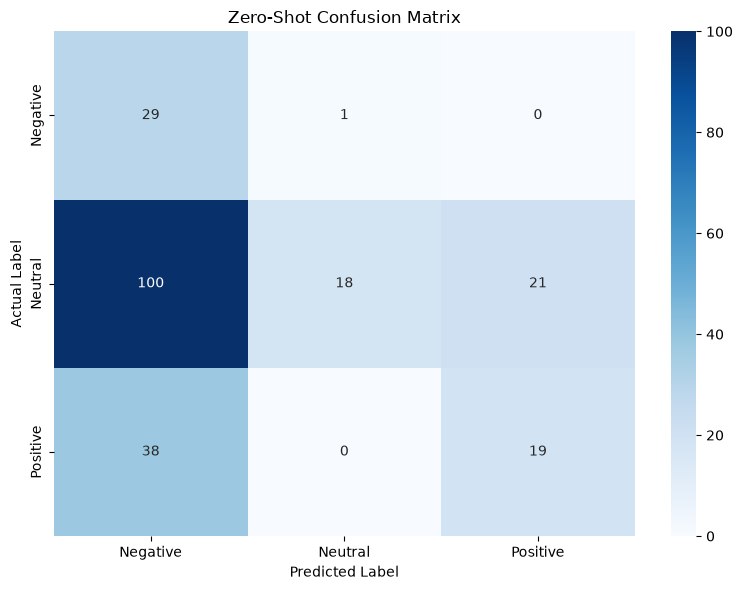

Negative    167
Positive     40
Neutral      19
Name: count, dtype: int64

In [110]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = ["Negative", "Neutral", "Positive"]

zero_shot_cm = confusion_matrix(
    y_true,
    zero_shot_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    zero_shot_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Zero-Shot Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/zero_shot_confusion_matrix.png", dpi=300)
plt.show()

pd.Series(zero_shot_predictions).map(model.config.id2label).value_counts()

In [111]:
def evaluate_predictions(model_name, y_true, y_pred):

    class_recalls = recall_score(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    return {
        "model": model_name,
        "samples": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, labels=[0, 1, 2],
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, labels=[0, 1, 2],
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, labels=[0, 1, 2],
            average="macro", zero_division=0
        ),
        "negative_recall": class_recalls[0],
        "neutral_recall": class_recalls[1],
        "positive_recall": class_recalls[2]
    }


comparison_df = pd.DataFrame([
    evaluate_predictions(
        "Fine-Tuned DistilBERT",
        y_true,
        predicted_labels.numpy()
    ),
    evaluate_predictions(
        "Zero-Shot DistilBERT",
        y_true,
        zero_shot_predictions
    )
])

comparison_df.to_csv(
    "../reports/fine_tuned_vs_zero_shot.csv",
    index=False
)

comparison_df

,model,samples,accuracy,macro_precision,macro_recall,macro_f1,negative_recall,neutral_recall,positive_recall
0,Fine-Tuned DistilBERT,226,0.969027,0.950717,0.967601,0.958797,0.966667,0.971223,0.964912
1,Zero-Shot DistilBERT,226,0.292035,0.532007,0.476499,0.304672,0.966667,0.129496,0.333333


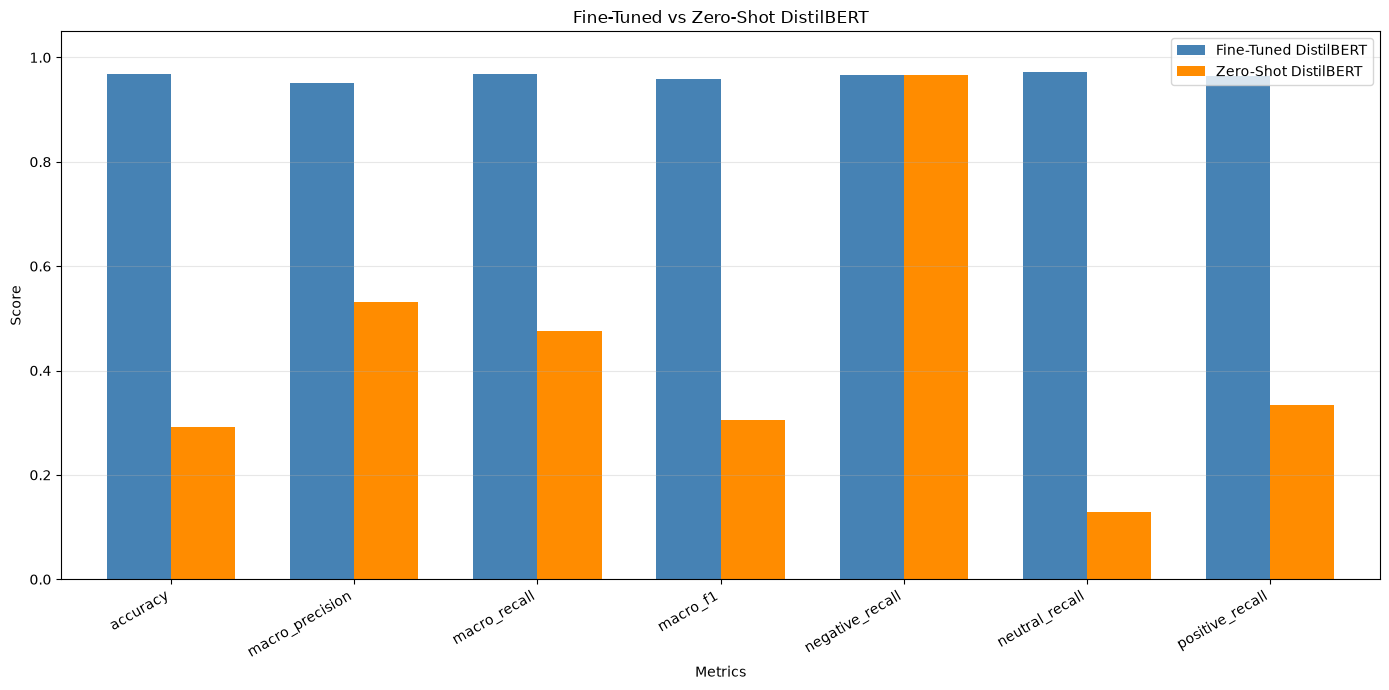

In [112]:
metrics = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall"
]

comparison_df.set_index("model")[metrics].T.plot(
    kind="bar",
    figsize=(14, 7),
    color=["steelblue", "darkorange"],
    width=0.7
)

plt.title("Fine-Tuned vs Zero-Shot DistilBERT")
plt.xlabel("Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/model_comparison.png", dpi=300)
plt.show()

In [113]:
assert len(y_true) == 226
assert len(predicted_labels) == len(zero_shot_predictions) == 226
assert set(zero_shot_predictions).issubset({0, 1, 2})
assert comparison_df.shape == (2, 9)
assert comparison_df[metrics].notna().all().all()

print("All comparison tests passed.")

All comparison tests passed.


In [114]:
from pathlib import Path
from sklearn.metrics import confusion_matrix

assert Path(CHECKPOINT).is_dir()
assert Path(model.name_or_path).resolve() == Path(CHECKPOINT).resolve()
assert model.config.model_type == "distilbert"
assert model.config.num_labels == 3
assert model.config.id2label == {0: "Negative", 1: "Neutral", 2: "Positive"}
assert MAX_LENGTH == 256

print("Test 1 — Checkpoint: PASSED")


assert len(val_df) == 226

assert np.array_equal(
    val_df["sentence"].to_numpy(),
    previous_predictions["sentence"].to_numpy()
)

assert np.array_equal(
    labels.numpy(),
    previous_predictions["actual_label"].to_numpy()
)

assert np.array_equal(
    predicted_labels.numpy(),
    previous_predictions["prediction_256"].to_numpy()
)

print("Test 2 — Validation Integrity: PASSED")


assert logits.shape == (226, 3)
assert labels.shape == (226,)
assert torch.isfinite(logits).all()

print("Test 3 — Logits Shape: PASSED")


assert probabilities.shape == (226, 3)
assert torch.all((probabilities >= 0) & (probabilities <= 1))

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(226),
    atol=1e-6
)

print("Test 4 — Probabilities: PASSED")


assert confidence.shape == (226,)
assert torch.isfinite(confidence).all()
assert torch.all((confidence >= 0) & (confidence <= 1))

assert torch.allclose(
    confidence,
    probabilities.max(dim=1).values
)

print("Test 5 — Confidence: PASSED")


test_confidence = torch.tensor([0.6, 0.6, 0.9, 0.9])
test_correct = torch.tensor([True, False, True, True])

test_ece, test_bins = calculate_ece(
    test_confidence,
    test_correct,
    n_bins=5
)

assert np.isclose(test_ece, 0.10, atol=1e-6)
assert test_bins["count"].sum() == 4

assert np.isfinite(overall_ece)
assert 0 <= overall_ece <= 1
assert bin_results["count"].sum() == 226

assert np.isfinite(classwise_df["ece"]).all()
assert classwise_df["ece"].between(0, 1).all()

for class_name, class_bins in classwise_bins.items():
    assert class_bins["count"].sum() == 226

print("Test 6 — Calibration: PASSED")


fine_tuned_cm = confusion_matrix(
    labels.numpy(),
    predicted_labels.numpy(),
    labels=[0, 1, 2]
)

cm_errors = fine_tuned_cm.sum() - np.trace(fine_tuned_cm)

assert cm_errors == 7
assert len(error_df) == cm_errors
assert incorrect_mask.sum().item() == cm_errors
assert len(error_report) == cm_errors

print("Test 7 — Error Consistency: PASSED")


assert len(zero_shot_results) == 226
assert len(zero_shot_predictions) == 226
assert len(predicted_labels) == 226

assert np.array_equal(y_true, labels.numpy())

assert np.array_equal(
    val_df["sentence"].to_numpy(),
    np.array([result["sequence"] for result in zero_shot_results])
)

assert set(zero_shot_predictions).issubset({0, 1, 2})

print("Test 8 — Zero-Shot Alignment: PASSED")

print("\nAll 8 tests passed successfully.")

Test 1 — Checkpoint: PASSED
Test 2 — Validation Integrity: PASSED
Test 3 — Logits Shape: PASSED
Test 4 — Probabilities: PASSED
Test 5 — Confidence: PASSED
Test 6 — Calibration: PASSED
Test 7 — Error Consistency: PASSED
Test 8 — Zero-Shot Alignment: PASSED

All 8 tests passed successfully.
